# Лабораторна робота №1: Лінійна регресія, оптимізація та статистичний аналіз

**Мета:** зрозуміти, як працює лінійна регресія "зсередини", самому написати градієнтний спуск на `numpy`,
вибрати корисні ознаки, порахувати якість моделі та перевірити статистичні припущення.

**Датасет:** Ames Housing. Файл `data/AmesHousing.csv` завантажено з Kaggle.

**План роботи:**
1. Дослідження даних (EDA), розбиття, відбір ознак, кодування, масштабування
2. Лінійна регресія на `numpy`
3. Три варіанти градієнтного спуску: Batch, SGD, Mini-batch
4. Оцінка якості: $R^2$ + бонус: Normal Equation
5. Перевірка статистичних припущень
6. Експеримент А: вплив масштабування

## 0. Бібліотеки

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

SEED = 42  # fixed seed so results are reproducible
np.random.seed(SEED)

## 1. Етап 1. Дослідження даних (EDA)

### 1.1 Завантаження даних

In [2]:
df = pd.read_csv('data/AmesHousing.csv')

# remove spaces and '/' from column names.
df.columns = df.columns.str.replace(' ', '').str.replace('/', '')

print('Shape:', df.shape)
df.head()

Shape: (2930, 82)


,Order,PID,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


Маємо 2930 будинків і 82 колонки: `Order` (номер рядка), `PID` (номер ділянки), цільову змінну `SalePrice`
(ціна продажу в доларах) та 79 ознак. У файлі назви колонок містять пробіли (`Gr Liv Area`), які були прибрані за допомогою `replace`.

### 1.2 Типи ознак

In [3]:
num_cols = df.select_dtypes(include='number').columns.drop(['Order', 'PID', 'SalePrice'])
cat_cols = df.select_dtypes(exclude='number').columns

print('Numeric features:', len(num_cols))
print('Categorical features:', len(cat_cols))
print('Examples numeric:', list(num_cols[:8]))
print('Examples categorical:', list(cat_cols[:8]))

Numeric features: 36
Categorical features: 43
Examples numeric: ['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea']
Examples categorical: ['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope']


Ознаки двох типів:
- **числові** — площа, рік будівництва, кількість кімнат тощо;
- **категоріальні** — текстові значення: район (`Neighborhood`), тип будинку (`BldgType`), якість кухні (`KitchenQual`) тощо.

Модель вміє множити тільки числа, тому категоріальні ознаки потрібно модифікувати.

### 1.3 Пропущені значення

In [4]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_table = pd.DataFrame({'count': missing, 'percent': (missing / len(df) * 100).round(1)})
missing_table

,count,percent
PoolQC,2917,99.6
MiscFeature,2824,96.4
Alley,2732,93.2
Fence,2358,80.5
MasVnrType,1775,60.6
FireplaceQu,1422,48.5
LotFrontage,490,16.7
GarageQual,159,5.4
GarageCond,159,5.4
GarageYrBlt,159,5.4


Пропуски є у 27 колонках. Найбільше їх у `PoolQC`, `MiscFeature`, `Alley`, `Fence` — понад 80%, і в `MasVnrType` — ~61%.
Але це не "помилки в даних": за описом датасету NaN тут означає "немає басейну", "немає паркану", "немає облицювання" тощо.
Ці колонки ми не будемо враховувати (дуже мало інформації). `LotFrontage` має ~17% пропусків,
а деякі колонки (`GarageCars`, `TotalBsmtSF` та ін.) — лише 1–2 пропуски; з ними проведемо роботу після відбору ознак.

### 1.4 Розподіл цільової змінної

In [5]:
df['SalePrice'].describe()

count      2930.000000
mean     180796.060068
std       79886.692357
min       12789.000000
25%      129500.000000
50%      160000.000000
75%      213500.000000
max      755000.000000
Name: SalePrice, dtype: float64

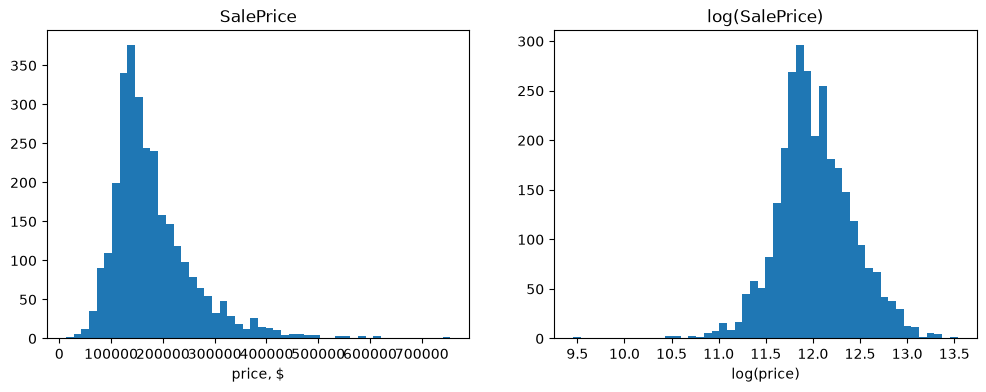

Skewness of SalePrice: 1.74
Skewness of log(SalePrice): -0.01


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['SalePrice'], bins=50)
axes[0].set_title('SalePrice')
axes[0].set_xlabel('price, $')

axes[1].hist(np.log(df['SalePrice']), bins=50)
axes[1].set_title('log(SalePrice)')
axes[1].set_xlabel('log(price)')

plt.show()

print('Skewness of SalePrice:', round(df['SalePrice'].skew(), 2))
print('Skewness of log(SalePrice):', round(np.log(df['SalePrice']).skew(), 2))

**Висновок.** Ціни мають довгий "хвіст" праворуч (асиметрія ~1.7): більшість будинків коштують 100–250 тис.,
але є кілька дуже дорогих. Після логарифма розподіл стає майже симетричним (асиметрія ~0.0).

Тому модель буде прогнозувати **log(SalePrice)**, а не саму ціну. Чому це добре:
- помилка в 20 тис. для будинку за 100 тис. і за 700 тис. — це різні речі; логарифм перетворює помилки на "відсоткові";
- залишки моделі будуть ближчими до нормального розподілу (це перевіримо на етапі 5);
- дорогі будинки менше "тягнуть" модель на себе.

### 1.5 Розбиття вибірки на Train / Validation / Test

Ділимо дані **на самому початку**, ще до відбору ознак, кодування і масштабування:
- **Train (70%)** — на ньому модель вчиться, і тільки на ньому ми рахуємо кореляції, середні, std тощо;
- **Validation (15%)** — на ньому підбираємо learning rate (гіперпараметри);
- **Test (15%)** — дивимося на нього лише в кінці, щоб чесно оцінити модель.

In [7]:
train_df, temp_df = train_test_split(df, test_size=0.3, random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=SEED)

print('Train:', train_df.shape)
print('Validation:', val_df.shape)
print('Test:', test_df.shape)

Train: (2051, 82)
Validation: (439, 82)
Test: (440, 82)


**Питання: чому ділимо дані ДО масштабування, кодування та інших операцій, які "вчаться" на даних? Що таке Data Leakage?**

**Витік даних (data leakage)** — це ситуація, коли під час навчання модель (або підготовка даних) "підглядає"
в інформацію з валідації чи тесту. Наприклад, якщо порахувати середнє і std для стандартизації по всьому датасету,
то в ці числа потрапить і тестова частина. Тоді тест вже не є "новими, невідомими" даними,
і оцінка якості вийде занадто оптимістичною. У реальному житті нових будинків ми наперед не бачимо,
тому і тут усе, що вчиться на даних (середні, std, список категорій, вибір ознак), рахуємо тільки на Train,
а потім просто застосовуємо до Validation і Test.

### 1.6 Викиди (outliers)

Перед відбором ознак подивимося на найважливішу пару — житлова площа і ціна.

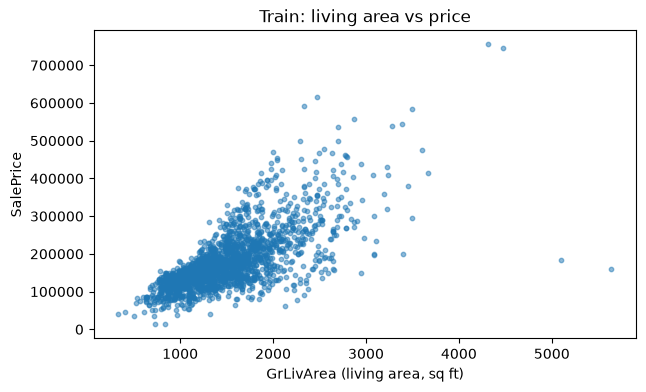

,GrLivArea,SalePrice
1498,5642,160000
2180,5095,183850


In [8]:
plt.figure(figsize=(7, 4))
plt.scatter(train_df['GrLivArea'], train_df['SalePrice'], s=10, alpha=0.5)
plt.xlabel('GrLivArea (living area, sq ft)')
plt.ylabel('SalePrice')
plt.title('Train: living area vs price')
plt.show()

outliers = train_df[(train_df['GrLivArea'] > 4000) & (train_df['SalePrice'] < 300000)]
outliers[['GrLivArea', 'SalePrice']]

Видно дві дивні точки праворуч внизу: величезні будинки (>5000 кв. футів) за дуже низькою ціною.
Обидва — продажі зі статусом `Partial` (будинок продали ще недобудованим).
Автор датасету (Dean De Cock) сам радить прибрати такі будинки — це нетипові продажі.
Лінійна регресія з MSE дуже чутлива до таких точок (помилка підноситься до квадрату), тому видаляємо їх,
але **тільки з Train**. Validation і Test не чіпаємо — там мають бути "чесні" дані.

In [9]:
train_df = train_df.drop(outliers.index)
print('Train after removing outliers:', train_df.shape)

Train after removing outliers: (2049, 82)


### 1.7 Відбір ознак (тільки на Train)

Порахуємо кореляцію Пірсона кожної числової ознаки з `SalePrice`.
Кореляція близька до 1 — сильний прямий лінійний зв'язок, близька до 0 — лінійного зв'язку немає.

In [10]:
corr_with_price = train_df[list(num_cols) + ['SalePrice']].corr()['SalePrice'].drop('SalePrice')
corr_with_price = corr_with_price.sort_values(ascending=False)
corr_with_price.head(15).round(3)

OverallQual     0.796
GrLivArea       0.721
TotalBsmtSF     0.647
GarageCars      0.641
1stFlrSF        0.635
GarageArea      0.631
FullBath        0.541
YearBuilt       0.540
YearRemodAdd    0.515
GarageYrBlt     0.512
MasVnrArea      0.503
TotRmsAbvGrd    0.489
Fireplaces      0.473
BsmtFinSF1      0.439
LotFrontage     0.347
Name: SalePrice, dtype: float64

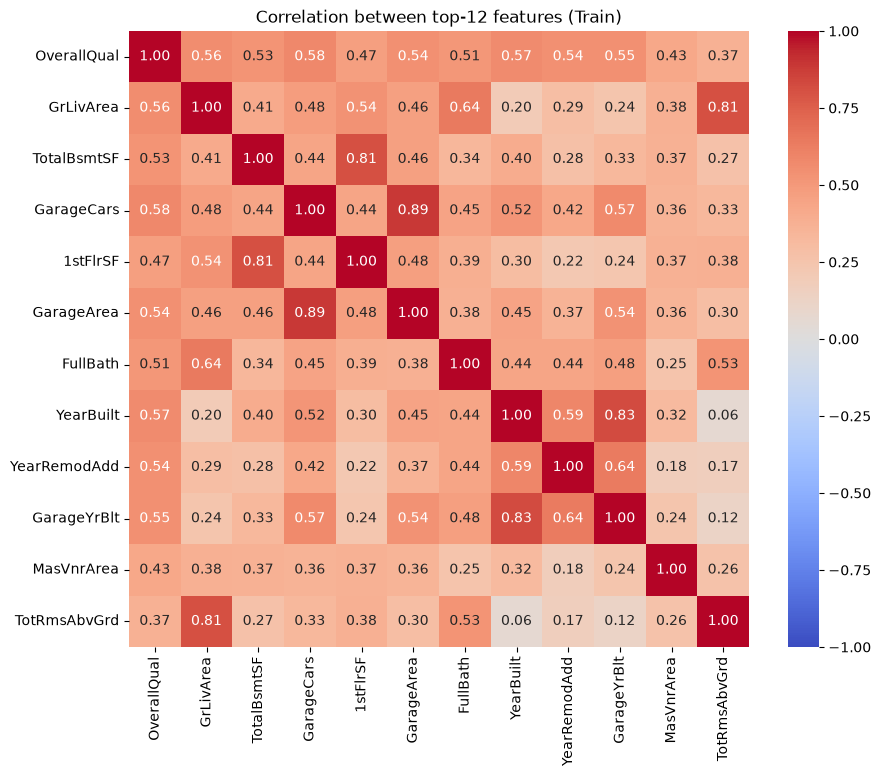

In [11]:
# correlation between the 12 best features themselves (looking for multicollinearity)
top12 = corr_with_price.head(12).index
plt.figure(figsize=(10, 8))
sns.heatmap(train_df[top12].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation between top-12 features (Train)')
plt.show()

**Що бачимо:**
- найсильніше з ціною пов'язані `OverallQual` (загальна якість, 0.80), `GrLivArea` (житлова площа, 0.72),
  `TotalBsmtSF` (площа підвалу), `GarageCars`, `1stFlrSF`, `GarageArea` (0.63–0.65);
- деякі ознаки майже дублюють одна одну:
  - `GarageCars` і `GarageArea` (~0.89) — скільки машин влазить і площа гаража — це майже одне й те саме;
  - `TotalBsmtSF` і `1stFlrSF` (~0.81) — площа підвалу ≈ площа першого поверху;
  - `GrLivArea` і `TotRmsAbvGrd` (~0.81) — більша площа = більше кімнат;
  - `YearBuilt` і `GarageYrBlt` (~0.83) — гараж зазвичай будують разом з будинком.

Якщо взяти обидві ознаки з пари, буде **мультиколінеарність**: модель не зможе зрозуміти, яка з двох ознак
"насправді" впливає, і коефіцієнти стануть нестабільними. Тому з кожної пари беремо одну — ту, що сильніше корелює з ціною.

**Обрані числові ознаки:** `OverallQual`, `GrLivArea`, `GarageCars`, `TotalBsmtSF`, `FullBath`, `YearBuilt`, `YearRemodAdd`.

`LotArea` (площа ділянки) з завдання не беремо: її кореляція з ціною слабка (~0.26), і в неї багато екстремальних значень.
`MasVnrArea` (0.50) теж не беремо: ~60% будинків взагалі не мають облицювання, тобто там просто нулі.
`MasVnrArea` (0.50) теж не беремо: ~60% будинків взагалі не мають облицювання, тобто там просто нулі.

Тепер подивимося на дві категоріальні ознаки, які, на нашу думку, сильно впливають на ціну.

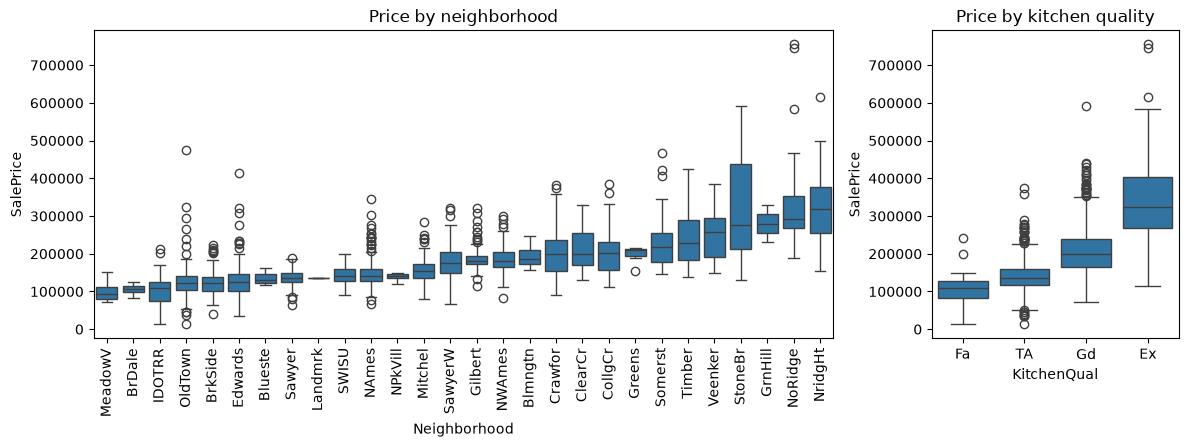

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={'width_ratios': [3, 1]})

order = train_df.groupby('Neighborhood')['SalePrice'].median().sort_values().index
sns.boxplot(data=train_df, x='Neighborhood', y='SalePrice', order=order, ax=axes[0])
axes[0].tick_params(axis='x', rotation=90)
axes[0].set_title('Price by neighborhood')

sns.boxplot(data=train_df, x='KitchenQual', y='SalePrice', order=['Fa', 'TA', 'Gd', 'Ex'], ax=axes[1])
axes[1].set_title('Price by kitchen quality')

plt.show()

**Висновок.** Медіанна ціна в найдешевшому районі (MeadowV, ~92 тис.) і найдорожчому (NridgHt, ~318 тис.) відрізняється більш ніж утричі —
район дуже важливий ("location, location, location"). Якість кухні теж чітко впорядкована: Fa < TA < Gd < Ex.

**Обрані категоріальні ознаки:** `Neighborhood`, `KitchenQual`.

Перевіримо, чи є пропуски в обраних колонках.

In [13]:
num_features = ['OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF', 'FullBath', 'YearBuilt', 'YearRemodAdd']
cat_features = ['Neighborhood', 'KitchenQual']
features = num_features + cat_features

print('Missing in train:', train_df[features].isna().sum()[lambda s: s > 0].to_dict())
print('Missing in val:  ', val_df[features].isna().sum()[lambda s: s > 0].to_dict())
print('Missing in test: ', test_df[features].isna().sum()[lambda s: s > 0].to_dict())

Missing in train: {'GarageCars': 1, 'TotalBsmtSF': 1}
Missing in val:   {}
Missing in test:  {}


У Train є по одному пропуску в `GarageCars` і `TotalBsmtSF` (у Validation і Test пропусків немає).
Заповнимо їх **медіаною з Train** — це робимо прямо у функції `get_numeric` нижче.
Для 2 значень з ~2000 вибір способу заповнення майже ні на що не впливає. (Чесно кажучи, будинок з пропуском у `TotalBsmtSF`
не має підвалу — `BsmtQual` теж NaN, тож логічніше було б поставити 0, але для одного будинку різниця мізерна.)

### 1.8 Кодування категоріальних ознак

- **`KitchenQual` → Ordinal Encoding.** Значення мають природний порядок (Po < Fa < TA < Gd < Ex),
  тому замінюємо їх числами 1…5. Так модель "розуміє", що Ex краще за Gd.
- **`Neighborhood` → One-Hot Encoding.** Райони не мають порядку (не можна сказати, що "NAmes > CollgCr").
  Якщо дати їм числа 1…28, модель вирішить, що район №20 "у 20 разів більший" за №1 — це нісенітниця.
  Тому кожен район стає окремою колонкою з 0 або 1.
- **Target Encoding** (заміна категорії на середню ціну в ній) не беремо: він легко дає витік даних
  (використовує саму ціну), а для 28 районів one-hot цілком достатньо.

**Питання: що робити з категоріями, яких не було в Train, але вони з'явилися у Validation/Test?**

Для one-hot ставимо `handle_unknown='ignore'`: невідомий район отримає рядок з одних нулів,
тобто модель використає для нього тільки bias та інші ознаки (по суті — "середній" район).
Для `KitchenQual` у словнику є всі 5 можливих значень з опису датасету, тому невідомих значень там не буде.

In [14]:
# check: are there neighborhoods in val/test that never appear in train?
train_neigh = set(train_df['Neighborhood'])
print('Unseen in val: ', set(val_df['Neighborhood']) - train_neigh)
print('Unseen in test:', set(test_df['Neighborhood']) - train_neigh)

Unseen in val:  set()
Unseen in test: set()


In [15]:
kitchen_map = {'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}

# learn the list of neighborhoods ONLY from train
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
ohe.fit(train_df[['Neighborhood']])
neigh_names = list(ohe.get_feature_names_out())
print('Number of one-hot columns:', len(neigh_names))


# medians for filling missing values are computed on train only
train_medians = train_df[num_features].median()


def get_numeric(part):
    # numeric features (missing -> train median) + ordinal-encoded kitchen quality
    numeric = part[num_features].fillna(train_medians).values.astype(float)
    kitchen = part['KitchenQual'].map(kitchen_map).values
    return np.column_stack([numeric, kitchen])

Number of one-hot columns: 28


### 1.9 Масштабування (стандартизація)

Ознаки мають дуже різний масштаб: `GrLivArea` ~ 1500, `YearBuilt` ~ 2000, `FullBath` ~ 2.
Для градієнтного спуску це погано (детально — в експерименті А на етапі 6).
Тому робимо **стандартизацію**: $z = \frac{x - \mu}{\sigma}$. Після неї кожна ознака має середнє 0 і std 1.

$\mu$ і $\sigma$ рахуємо **тільки на Train** і ті самі числа застосовуємо до Validation і Test.
One-hot колонки не масштабуємо — вони вже 0/1.

In [16]:
numeric_names = num_features + ['KitchenQual']

# scaling parameters are computed on train only
mu = get_numeric(train_df).mean(axis=0)
sigma = get_numeric(train_df).std(axis=0)


def build_X(part, scale=True):
    numeric = get_numeric(part)
    if scale:
        numeric = (numeric - mu) / sigma
    neigh = ohe.transform(part[['Neighborhood']])
    return np.hstack([numeric, neigh])


X_train, X_val, X_test = build_X(train_df), build_X(val_df), build_X(test_df)
y_train = np.log(train_df['SalePrice'].values)
y_val = np.log(val_df['SalePrice'].values)
y_test = np.log(test_df['SalePrice'].values)

feature_names = numeric_names + neigh_names
print('X_train:', X_train.shape, ' X_val:', X_val.shape, ' X_test:', X_test.shape)
print('Mean of scaled train features (first 8):', X_train[:, :8].mean(axis=0).round(3))
print('Std of scaled train features (first 8): ', X_train[:, :8].std(axis=0).round(3))

X_train: (2049, 36)  X_val: (439, 36)  X_test: (440, 36)
Mean of scaled train features (first 8): [ 0.  0.  0.  0. -0. -0.  0. -0.]
Std of scaled train features (first 8):  [1. 1. 1. 1. 1. 1. 1. 1.]


Після стандартизації середні на Train = 0, std = 1. На Validation/Test вони будуть *близькі*, але не рівно 0 і 1 —
це нормально, бо ми використали параметри з Train.

---
## 2. Етап 2. Лінійна регресія засобами numpy

Модель (лекція 1, "Linear Regression: The Hypothesis"):

$$\hat{y} = Xw + b$$

- $X$ — матриця ознак розміру $m \times n$ ($m$ будинків, $n$ ознак);
- $w$ — вектор ваг (по одній вазі на кожну ознаку), $b$ — зсув (bias).

**Функція втрат (MSE)** — середня квадратична помилка (множник $\frac{1}{2}$ — щоб похідна була гарнішою):

$$J(w, b) = \frac{1}{2m} \sum_{i=1}^{m} (\hat{y}^{(i)} - y^{(i)})^2$$

**Градієнти** — куди і наскільки сильно зростає $J$, якщо трохи змінити $w$ чи $b$:

$$\frac{\partial J}{\partial w} = \frac{1}{m} X^T(\hat{y} - y), \qquad \frac{\partial J}{\partial b} = \frac{1}{m} \sum_{i=1}^{m}(\hat{y}^{(i)} - y^{(i)})$$

**Оновлення параметрів** — робимо крок проти градієнта (вниз по "чаші"):

$$w := w - \alpha \frac{\partial J}{\partial w}, \qquad b := b - \alpha \frac{\partial J}{\partial b}$$

Жодних циклів `for` по прикладах — усе через матричні операції (`@`, `.mean()`).

In [17]:
def predict(X, w, b):
    return X @ w + b


def compute_cost(X, y, w, b):
    m = len(y)
    error = predict(X, w, b) - y
    return (error @ error) / (2 * m)  # error @ error = sum of squared errors


def compute_gradients(X, y, w, b):
    m = len(y)
    error = predict(X, w, b) - y
    dw = X.T @ error / m
    db = error.mean()
    return dw, db


def update_params(w, b, dw, db, lr):
    w = w - lr * dw
    b = b - lr * db
    return w, b

**Перевірка градієнта.** Щоб переконатися, що формула градієнта правильна, порівняємо її з чисельною похідною:
$\frac{J(w + \varepsilon) - J(w - \varepsilon)}{2\varepsilon}$ для однієї ваги. Числа мають майже збігтися.

In [18]:
w_test = np.random.randn(X_train.shape[1]) * 0.1
b_test = 0.5
eps = 1e-5

dw, db = compute_gradients(X_train, y_train, w_test, b_test)

w_plus, w_minus = w_test.copy(), w_test.copy()
w_plus[0] += eps
w_minus[0] -= eps
numeric_dw0 = (compute_cost(X_train, y_train, w_plus, b_test) - compute_cost(X_train, y_train, w_minus, b_test)) / (2 * eps)

print('Analytic dw[0]:', dw[0])
print('Numeric  dw[0]:', numeric_dw0)
assert abs(dw[0] - numeric_dw0) < 1e-6

Analytic dw[0]: -0.04467583264419693
Numeric  dw[0]: -0.04467583281098086


---
## 3. Етап 3. Градієнтний спуск: три варіанти

Три варіанти відрізняються лише тим, **скільки прикладів беремо для одного кроку** (лекція 1, "The Gradient Descent Family"):

| Метод | Розмір батчу | Кроків за 1 епоху |
|---|---|---|
| Batch GD | всі $m$ прикладів | 1 |
| SGD | 1 приклад | $m$ |
| Mini-batch GD | $B$ прикладів (беремо $B = 32$) | $m / B$ |

Тому пишемо **одну** функцію з параметром `batch_size`:
`batch_size = m` → Batch GD, `batch_size = 1` → SGD, `batch_size = 32` → Mini-batch.

**Епоха** — один повний прохід по всіх даних Train. Перед кожною епохою перемішуємо дані,
щоб батчі щоразу були різними. Після кожної епохи запам'ятовуємо cost на всьому Train.

**Критерій зупинки:**
- максимум `epochs` епох;
- або cost майже не змінюється: $|J_{t-1} - J_t| < 10^{-7}$ — модель вже зійшлася;
- або cost став `inf`/`nan` — алгоритм розійшовся, далі вчити немає сенсу.

In [19]:
def train_gd(X, y, lr, epochs, batch_size, tol=1e-7):
    rng = np.random.default_rng(SEED)
    m, n = X.shape
    w = np.zeros(n)
    b = 0.0
    history = [compute_cost(X, y, w, b)]

    for epoch in range(epochs):
        indices = rng.permutation(m)  # shuffle before every epoch
        for start in range(0, m, batch_size):
            batch = indices[start:start + batch_size]
            dw, db = compute_gradients(X[batch], y[batch], w, b)
            w, b = update_params(w, b, dw, db, lr)

        history.append(compute_cost(X, y, w, b))

        if not np.isfinite(history[-1]):  # diverged
            break
        if abs(history[-2] - history[-1]) < tol:  # converged
            break

    return w, b, history

### 3.1 Підбір learning rate ($\alpha$)

Для кожного методу пробуємо кілька значень $\alpha$, вчимо модель на Train і дивимося cost на **Validation**.
Найкраще $\alpha$ — те, що дає найменший cost на Validation.

In [20]:
EPOCHS = 500
B = 32
m_train = len(y_train)

methods = {
    'Batch GD': m_train,
    'SGD': 1,
    'Mini-batch GD': B,
}

lr_grid = {
    'Batch GD': [0.01, 0.1, 0.3, 0.5],
    'SGD': [0.0001, 0.001, 0.003, 0.01],
    'Mini-batch GD': [0.001, 0.01, 0.03, 0.1],
}

rows = []
for name, batch_size in methods.items():
    for lr in lr_grid[name]:
        w, b, history = train_gd(X_train, y_train, lr, EPOCHS, batch_size)
        rows.append({
            'method': name,
            'lr': lr,
            'epochs_run': len(history) - 1,
            'train_cost': history[-1],
            'val_cost': compute_cost(X_val, y_val, w, b),
        })

lr_results = pd.DataFrame(rows)
lr_results

,method,lr,epochs_run,train_cost,val_cost
0,Batch GD,0.0100,500,6.603702e-02,6.382061e-02
1,Batch GD,0.1000,500,1.348074e-02,1.175170e-02
2,Batch GD,0.3000,500,1.122209e-02,9.118680e-03
3,Batch GD,0.5000,500,5.390198e+66,5.971562e+66
4,SGD,0.0001,500,1.161977e-02,9.554271e-03
5,SGD,0.0010,103,1.104124e-02,8.960660e-03
6,SGD,0.0030,500,1.080147e-02,9.114628e-03
7,SGD,0.0100,500,1.115554e-02,9.356856e-03
8,Mini-batch GD,0.0010,500,1.583591e-02,1.452938e-02
9,Mini-batch GD,0.0100,500,1.113218e-02,9.204537e-03


In [21]:
# best learning rate for each method = smallest validation cost
best_lr = lr_results.loc[lr_results.groupby('method')['val_cost'].idxmin()].set_index('method')['lr']
best_lr

method
Batch GD         0.300
Mini-batch GD    0.010
SGD              0.001
Name: lr, dtype: float64

**Висновок по підбору $\alpha$:**
- **Batch GD:** $\alpha = 0.01$ — замало: за 500 епох cost ще 0.066 (у 6 разів більше за найкращий).
  $\alpha = 0.5$ — алгоритм **розійшовся**: cost виріс до ~$10^{66}$. Найкраще $\alpha = 0.3$.
- **SGD:** потрібні набагато менші $\alpha$, бо кожен крок робиться по одному будинку (шумний градієнт),
  а кроків за епоху аж ~2000. Найкраще $\alpha = 0.001$; при більших $\alpha$ cost на Validation вже гірший — модель "стрибає" навколо мінімуму.
- **Mini-batch:** найкраще $\alpha = 0.01$; при $\alpha = 0.1$ cost на Validation утричі гірший (0.029 проти 0.0092) — кроки завеликі.

Загальне правило: чим менше прикладів у батчі, тим менший має бути $\alpha$.
Деякі запуски закінчились раніше 500 епох — спрацював критерій зупинки $|\Delta J| < 10^{-7}$.

### 3.2 Навчання з найкращими $\alpha$ і графік функції втрат

In [22]:
models = {}
histories = {}
for name, batch_size in methods.items():
    w, b, history = train_gd(X_train, y_train, best_lr[name], EPOCHS, batch_size)
    models[name] = (w, b)
    histories[name] = history
    print(f'{name:14s} lr={best_lr[name]:<7} epochs={len(history) - 1:<4} final train cost={history[-1]:.5f}')

Batch GD       lr=0.3     epochs=500  final train cost=0.01122


SGD            lr=0.001   epochs=103  final train cost=0.01104


Mini-batch GD  lr=0.01    epochs=500  final train cost=0.01113


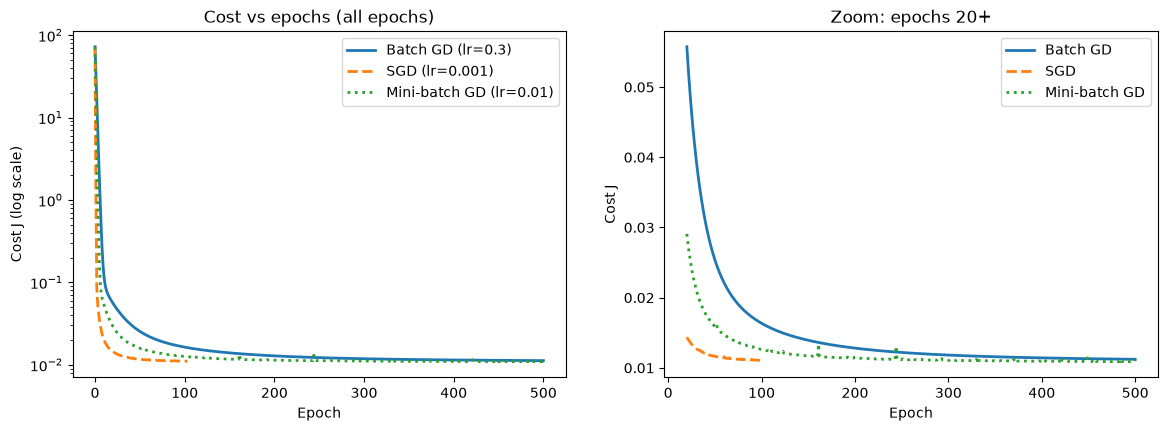

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
styles = {'Batch GD': '-', 'SGD': '--', 'Mini-batch GD': ':'}

for name, history in histories.items():
    axes[0].plot(history, styles[name], linewidth=2, label=f'{name} (lr={best_lr[name]})')
axes[0].set_yscale('log')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cost J (log scale)')
axes[0].set_title('Cost vs epochs (all epochs)')
axes[0].legend()

# zoom on the end of training to see small oscillations
for name, history in histories.items():
    axes[1].plot(range(20, len(history)), history[20:], styles[name], linewidth=2, label=name)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Cost J')
axes[1].set_title('Zoom: epochs 20+')
axes[1].legend()

plt.show()

**Що бачимо на графіку:**
- Усі три методи приходять до майже однакового cost ≈ 0.0110–0.0112. Це логічно: MSE для лінійної регресії —
  опукла "чаша" з одним мінімумом (лекція 1, "Convergence in the Convex Bowl").
- **SGD** приходить до мінімуму найшвидше (~60–100 епох), **Mini-batch** — за ~150–200, а **Batch GD** — лише за ~400 епох.
  Причина: за одну епоху Batch GD робить 1 крок, Mini-batch — 64 кроки (2049 / 32), а SGD — 2049 кроків.

**Відповіді на питання:**
1. **Найстабільніше збігається Batch GD:** крива гладка і весь час спадає, бо градієнт рахується точно, по всіх даних.
2. **Найбільші коливання — у SGD:** градієнт по одному будинку — дуже "шумна" оцінка справжнього градієнта.
   На правому графіку у Mini-batch видно окремі маленькі "сплески" (близько 160-ї та 245-ї епохи), а лінія Batch GD гладка
   (детальніше про шум — на графіку нижче).
3. **Розмір батчу:** менший батч → більше кроків за епоху → швидше за епохами, але більше шуму, і потрібен менший $\alpha$.
   Більший батч → точніший градієнт і стабільніше, але повільніше за епохами.
   Mini-batch — компроміс: майже така ж швидкість, як у SGD, і при цьому швидко рахується завдяки векторизації
   (32 приклади обробляються однією матричною операцією, а не 32 окремими кроками).
4. **Learning rate:** замалий $\alpha$ → дуже повільно (Batch GD з $\alpha = 0.01$); завеликий → розходиться
   (Batch GD з $\alpha = 0.5$); для SGD/Mini-batch завеликий $\alpha$ ще й дає сильні коливання біля мінімуму.

Графік по епохах "згладжує" шум, бо cost рахуємо лише раз за епоху. Щоб побачити, як поводиться кожен окремий крок,
стартуємо **з уже навченої моделі Batch GD** (тобто майже з дна "чаші") і робимо ще кроки SGD та Mini-batch,
записуючи cost на всьому Train **після кожного кроку**.

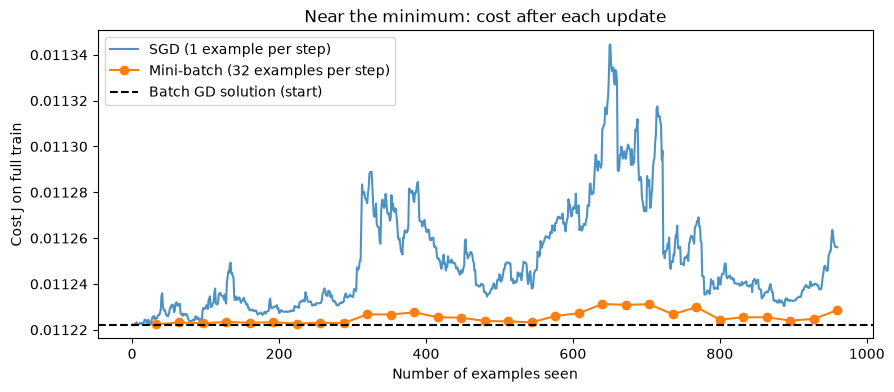

SGD cost range:        0.01122 - 0.01134
Mini-batch cost range: 0.01122 - 0.01123


In [24]:
def cost_after_each_step(X, y, w, b, lr, batch_size, steps):
    rng = np.random.default_rng(SEED)
    indices = rng.permutation(len(y))
    costs = []
    for step in range(steps):
        batch = indices[step * batch_size:(step + 1) * batch_size]
        dw, db = compute_gradients(X[batch], y[batch], w, b)
        w, b = update_params(w, b, dw, db, lr)
        costs.append(compute_cost(X, y, w, b))
    return costs


# start from the Batch GD solution, which is already near the minimum
w0, b0 = models['Batch GD']
start_cost = compute_cost(X_train, y_train, w0, b0)

# 960 SGD steps and 30 mini-batch steps both use 960 examples
sgd_steps = cost_after_each_step(X_train, y_train, w0, b0, best_lr['SGD'], 1, 960)
mb_steps = cost_after_each_step(X_train, y_train, w0, b0, best_lr['Mini-batch GD'], B, 30)

plt.figure(figsize=(10, 4))
plt.plot(np.arange(1, 961), sgd_steps, label='SGD (1 example per step)', alpha=0.8)
plt.plot(np.arange(1, 31) * B, mb_steps, 'o-', label='Mini-batch (32 examples per step)')
plt.axhline(start_cost, color='black', linestyle='--', label='Batch GD solution (start)')
plt.xlabel('Number of examples seen')
plt.ylabel('Cost J on full train')
plt.title('Near the minimum: cost after each update')
plt.legend()
plt.show()

print('SGD cost range:       ', round(min(sgd_steps), 5), '-', round(max(sgd_steps), 5))
print('Mini-batch cost range:', round(min(mb_steps), 5), '-', round(max(mb_steps), 5))

**Висновок.** Пунктирна лінія — рішення Batch GD: кожен його крок точний, тому біля мінімуму він стоїть на місці.
А SGD і Mini-batch, навіть стартуючи з дна "чаші", не можуть там залишитися: кожен їхній крок зроблено по неповних
даних, тому вони "блукають" навколо мінімуму. У SGD крива дуже зубчаста і cost коливається між 0.01122 і 0.01134
(кожен крок — новий випадковий будинок). Mini-batch з $\alpha = 0.01$ майже стоїть на місці (0.01122–0.01123):
градієнт усереднено по 32 будинках, тому він точніший, а крок маленький.
Тому для стохастичних методів часто поступово зменшують $\alpha$ під час навчання (learning rate decay).

---
## 4. Етап 4. Оцінка якості: коефіцієнт детермінації $R^2$

$$R^2 = 1 - \frac{\sum_{i=1}^{m}(y^{(i)} - \hat{y}^{(i)})^2}{\sum_{i=1}^{m}(y^{(i)} - \bar{y})^2}$$

- Знаменник — наскільки ціни "розкидані" навколо середнього (помилка найтупішої моделі, яка завжди каже $\bar{y}$).
- Чисельник — помилка нашої моделі.
- $R^2$ показує, **яку частку розкиду (дисперсії) цільової змінної пояснює модель**.
  $R^2 = 1$ — ідеальна модель, $R^2 = 0$ — модель не краща за середнє.

In [25]:
def r2_score(y, y_hat):
    ss_res = np.sum((y - y_hat) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    return 1 - ss_res / ss_tot


r2_rows = []
for name, (w, b) in models.items():
    r2_rows.append({
        'method': name,
        'R2 train': r2_score(y_train, predict(X_train, w, b)),
        'R2 val': r2_score(y_val, predict(X_val, w, b)),
        'R2 test': r2_score(y_test, predict(X_test, w, b)),
    })

r2_table = pd.DataFrame(r2_rows).set_index('method').round(4)
r2_table

,R2 train,R2 val,R2 test
method,,,
Batch GD,0.8619,0.8956,0.8544
SGD,0.8642,0.8974,0.8580
Mini-batch GD,0.8630,0.8947,0.8619


**Чи може $R^2$ бути від'ємним?** Так. $R^2 < 0$, коли помилка моделі більша, ніж помилка "моделі", яка завжди
прогнозує середнє $\bar{y}$. Таке буває, якщо модель погано навчена (замалий learning rate, мало епох),
сильно перенавчена, або коли рахуємо $R^2$ на нових даних, на яких модель працює гірше за середнє.
Приклад з нашої роботи — Batch GD з $\alpha = 0.01$ і лише 100 епохами (дивись нижче): ваги стартують з нуля,
тобто спочатку модель прогнозує log-ціну = 0 замість ~12, і за 100 маленьких кроків вона ще навіть не дійшла до середнього.

In [26]:
w_bad, b_bad, _ = train_gd(X_train, y_train, 0.01, 100, m_train)
print('Batch GD, lr=0.01, 100 epochs -> R2 on val:', round(r2_score(y_val, predict(X_val, w_bad, b_bad)), 3))

Batch GD, lr=0.01, 100 epochs -> R2 on val: -96.917


**Висновки по $R^2$:**
- Усі три методи дають майже однакову якість: $R^2 \approx 0.86$ на Train, $\approx 0.90$ на Validation і $\approx 0.86$ на Test.
  Тобто модель пояснює ~86–90% розкиду логарифма ціни. Різниця між методами — в третьому знаку, це практично шум.
- **Train vs Test:** значення майже однакові (а Validation навіть вищий — у цю випадкову частину просто потрапило менше "дивних" продажів).
  Отже **перенавчання (overfitting) немає**. Модель скоріше трохи **недонавчена (underfitting)**: лінійна модель на 8 ознаках + район
  не може описати все (наприклад, нелінійні ефекти). Покращити можна, додавши ознаки або поліноміальні ознаки (лекція 2).
- Однакова якість трьох методів очікувана: функція втрат опукла, тому всі методи приходять в один і той самий мінімум —
  відрізняються лише шлях і швидкість.

---
## Бонус: Normal Equation (аналітичний розв'язок)

Градієнтний спуск іде до мінімуму маленькими кроками. Але для лінійної регресії з MSE мінімум можна знайти
**однією формулою**, без кроків. Тут ми її виводимо і перевіряємо, але модель для решти роботи все одно вчимо
градієнтними методами (як вимагає завдання).

### Виведення

**Крок 1. "Ховаємо" bias у ваги.** Додаємо до $X$ першу колонку з одиниць: $\tilde{X} = [\mathbf{1}, X]$,
а параметри записуємо одним вектором $\theta = [b, w_1, \dots, w_n]$. Тоді $\hat{y} = \tilde{X}\theta$.

**Крок 2. Записуємо функцію втрат у векторному вигляді:**

$$J(\theta) = \frac{1}{2m}(\tilde{X}\theta - y)^T(\tilde{X}\theta - y)
= \frac{1}{2m}\left(\theta^T\tilde{X}^T\tilde{X}\theta - 2\theta^T\tilde{X}^T y + y^T y\right)$$

**Крок 3. Беремо градієнт** (правила: $\nabla_\theta(\theta^T A \theta) = 2A\theta$ для симетричної $A$, $\nabla_\theta(\theta^T c) = c$):

$$\nabla_\theta J = \frac{1}{m}\left(\tilde{X}^T\tilde{X}\theta - \tilde{X}^T y\right) = \frac{1}{m}\tilde{X}^T(\tilde{X}\theta - y)$$

Це той самий градієнт, що й у нашій функції `compute_gradients` на етапі 2.

**Крок 4. На дні "чаші" градієнт дорівнює нулю:**

$$\tilde{X}^T\tilde{X}\theta = \tilde{X}^T y \quad\Rightarrow\quad \theta = (\tilde{X}^T\tilde{X})^{-1}\tilde{X}^T y$$

Тобто градієнтний спуск *крок за кроком іде* туди, де градієнт = 0, а Normal Equation *одразу стрибає* туди.

### Перевірка на наших даних

In [27]:
# add a column of ones so that b becomes just another weight
X_train_b = np.column_stack([np.ones(len(X_train)), X_train])
XtX = X_train_b.T @ X_train_b

print('Number of columns:', X_train_b.shape[1])
print('Rank of X:        ', np.linalg.matrix_rank(X_train_b))
print('Condition number of XtX:', f'{np.linalg.cond(XtX):.2e}')

Number of columns: 37
Rank of X:         36
Condition number of XtX: 5.99e+17


Колонок 37, а ранг лише 36 — тобто одна колонка є лінійною комбінацією інших, і матриця $\tilde{X}^T\tilde{X}$ **необоротна (вироджена)**.
Причина — **пастка фіктивних змінних (dummy variable trap)**: кожен будинок знаходиться рівно в одному районі,
тому сума 28 one-hot колонок завжди дорівнює 1 — а це точно колонка з одиниць для bias.
Величезне число обумовленості (~$6 \cdot 10^{17}$) підтверджує це. Подивимося, що буде, якщо "в лоб" порахувати обернену матрицю.

In [28]:
theta_inv = np.linalg.inv(XtX) @ X_train_b.T @ y_train  # numpy does not raise an error here...
print('R2 train with np.linalg.inv:', round(r2_score(y_train, X_train_b @ theta_inv), 2))  # ...but the result is garbage

R2 train with np.linalg.inv: -7816.68


`numpy` навіть не видав помилку (через похибки округлення матриця "майже" оборотна), але результат — повне сміття:
$R^2$ сильно від'ємний. Тому замість звичайної оберненої використовуємо **псевдообернену матрицю** `np.linalg.pinv`,
яка коректно працює і з виродженими матрицями (серед усіх розв'язків вибирає той, де ваги найменші).

In [29]:
theta = np.linalg.pinv(X_train_b) @ y_train


def add_ones(X):
    return np.column_stack([np.ones(len(X)), X])


ne_row = {
    'method': 'Normal Equation (pinv)',
    'R2 train': r2_score(y_train, X_train_b @ theta),
    'R2 val': r2_score(y_val, add_ones(X_val) @ theta),
    'R2 test': r2_score(y_test, add_ones(X_test) @ theta),
}
pd.concat([r2_table, pd.DataFrame([ne_row]).set_index('method').round(4)])

,R2 train,R2 val,R2 test
method,,,
Batch GD,0.8619,0.8956,0.8544
SGD,0.8642,0.8974,0.8580
Mini-batch GD,0.8630,0.8947,0.8619
Normal Equation (pinv),0.8698,0.9003,0.8644


In [30]:
w_mb, b_mb = models['Mini-batch GD']
print('Train cost, Normal Equation:', round(compute_cost(X_train, y_train, theta[1:], theta[0]), 5))
print('Train cost, Mini-batch GD:  ', round(compute_cost(X_train, y_train, w_mb, b_mb), 5))
diff = np.abs(predict(X_train, w_mb, b_mb) - X_train_b @ theta)
print('Median difference in predictions (log price):', round(np.median(diff), 3))
print('Max difference in predictions (log price):   ', round(diff.max(), 3))
print('House with max difference:', train_df.iloc[diff.argmax()][['Neighborhood', 'GrLivArea', 'SalePrice']].to_dict())
print('Houses from this neighborhood in train:', (train_df['Neighborhood'] == train_df.iloc[diff.argmax()]['Neighborhood']).sum())

Train cost, Normal Equation: 0.01058
Train cost, Mini-batch GD:   0.01113
Median difference in predictions (log price): 0.02
Max difference in predictions (log price):    0.659
House with max difference: {'Neighborhood': 'GrnHill', 'GrLivArea': 1295, 'SalePrice': 230000}
Houses from this neighborhood in train: 2


**Висновок.** Normal Equation дає практично ту саму якість, що й наші градієнтні методи ($R^2$ ≈ 0.87 / 0.90 / 0.86),
а cost на Train трохи менший (0.0106 проти 0.0111) — це точний мінімум, до якого GD лише наближається.
Для типового будинку прогнози відрізняються лише на ~0.02 (≈ 2% ціни), отже градієнтний спуск реалізовано правильно.

Найбільша різниця (~0.66) — у будинку з району `GrnHill`, де в Train лише 2 будинки. Вага цього району отримує градієнт
тільки від 2 прикладів з ~2000, тому GD вчить її дуже повільно ("пологий" напрямок у чаші), а Normal Equation розв'язує все одразу і точно.

### Обмеження Normal Equation

1. **Потрібна оборотність $X^TX$.** Не працює, якщо ознаки лінійно залежні (як у нас з one-hot + bias)
   або якщо ознак більше, ніж прикладів ($n > m$). Рятують: видалити одну категорію (`OneHotEncoder(drop='first')`),
   `pinv`, або Ridge: $(X^TX + \lambda I)^{-1}X^Ty$ — така матриця оборотна завжди.
2. **Дорого для багатьох ознак.** Обернення матриці $n \times n$ коштує ~$O(n^3)$ операцій, а сама $X^TX$ займає $n^2$ пам'яті.
   Для 34 ознак це миттєво, для 100 000 — нереально. Градієнтний спуск коштує ~$O(mn)$ за епоху.
3. **Числова нестабільність.** Якщо ознаки сильно корелюють, число обумовленості велике і результат неточний (ми це побачили).
4. **Працює лише для лінійної регресії з MSE.** Для логістичної регресії, нейромереж тощо формули "в одну дію" немає —
   там потрібен градієнтний спуск.
5. **Потрібні всі дані в пам'яті одразу.** Не можна вчитися "на льоту" по нових прикладах, як у SGD.

**Переваги:** немає learning rate, епох і критерію зупинки, масштабування ознак не обов'язкове.

---
## 5. Етап 5. Перевірка статистичних припущень

Лінійна регресія — це ще й статистична модель, яка припускає певні речі про **залишки** (residuals)
$\varepsilon = y - \hat{y}$. Перевіряємо їх на Train для моделі Mini-batch GD.

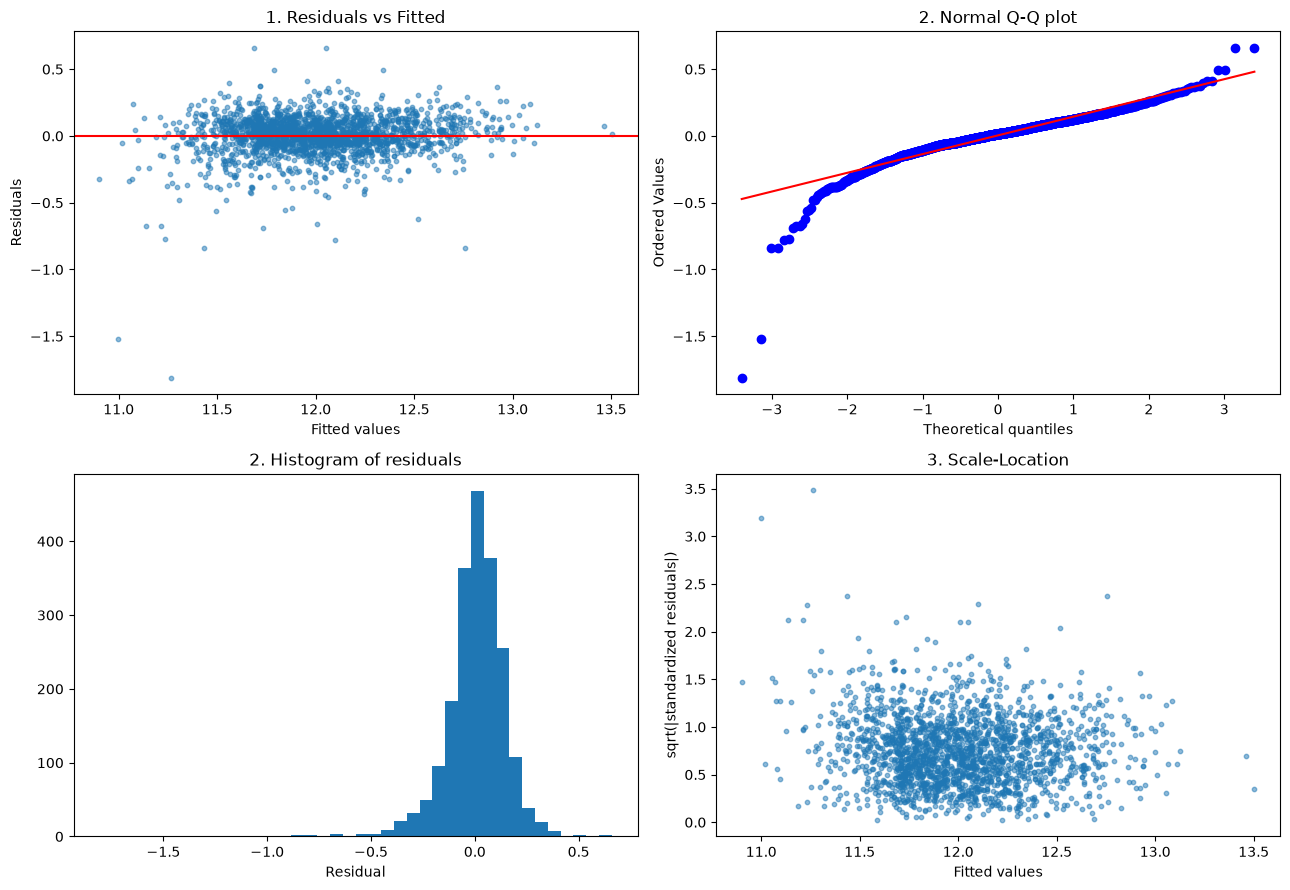

Shapiro-Wilk: W = 0.8842, p-value = 1.23e-36
Skewness of residuals: -2.104


In [31]:
w_mb, b_mb = models['Mini-batch GD']
fitted = predict(X_train, w_mb, b_mb)
residuals = y_train - fitted
std_residuals = residuals / residuals.std()  # standardized residuals

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1. Linearity
axes[0, 0].scatter(fitted, residuals, s=10, alpha=0.5)
axes[0, 0].axhline(0, color='red')
axes[0, 0].set_xlabel('Fitted values')
axes[0, 0].set_ylabel('Residuals')
axes[0, 0].set_title('1. Residuals vs Fitted')

# 2. Normality: Q-Q plot
stats.probplot(residuals, dist='norm', plot=axes[0, 1])
axes[0, 1].set_title('2. Normal Q-Q plot')

# 2. Normality: histogram
axes[1, 0].hist(residuals, bins=40)
axes[1, 0].set_xlabel('Residual')
axes[1, 0].set_title('2. Histogram of residuals')

# 3. Homoscedasticity: Scale-Location
axes[1, 1].scatter(fitted, np.sqrt(np.abs(std_residuals)), s=10, alpha=0.5)
axes[1, 1].set_xlabel('Fitted values')
axes[1, 1].set_ylabel('sqrt(|standardized residuals|)')
axes[1, 1].set_title('3. Scale-Location')

plt.tight_layout()
plt.show()

shapiro_stat, shapiro_p = stats.shapiro(residuals)
print(f'Shapiro-Wilk: W = {shapiro_stat:.4f}, p-value = {shapiro_p:.2e}')
print('Skewness of residuals:', round(stats.skew(residuals), 3))

**1. Лінійність (Residuals vs Fitted).** Припущення **виконується**, тому що точки розкидані хмарою навколо нуля
без видимої "дуги" чи іншої форми. Це означає, що лінійна модель (на log-ціні) правильно описує основну залежність
і явної нелінійності ми не пропустили.

**2. Нормальність залишків (Q-Q plot, гістограма, тест Шапіро-Уїлка).** Припущення **порушується**, тому що:
- тест Шапіро-Уїлка дає p-value ≈ $10^{-36}$, що набагато менше за 0.05 — гіпотезу про нормальність відкидаємо;
- на Q-Q plot ліві точки йдуть помітно нижче червоної лінії — "важкий" лівий хвіст;
- асиметрія залишків ≈ −2.1.

Це означає, що є будинки, які продали **значно дешевше**, ніж передбачає модель. Два найгірші — будинки, продані
за 12 789 і 13 100 доларів зі статусом `SaleCondition = Abnorml` (продаж через борги, викуп банком тощо):
залишок ≈ −1.5…−1.8, тобто реальна ціна у 5–6 разів нижча за прогноз. Середина розподілу при цьому майже нормальна.
На самі прогнози це впливає мало, але довірчі інтервали та p-values для коефіцієнтів були б неточними.
Також варто пам'ятати, що на ~1000 точках тест Шапіро-Уїлка "ловить" навіть невеликі відхилення.

**3. Гомоскедастичність (Scale-Location).** Припущення **приблизно виконується**, тому що хмара точок має приблизно
однакову висоту вздовж усієї осі X, без "лійки". Лише серед дешевих будинків (fitted < 11.5) є трохи більше великих залишків.
Це означає, що помилка моделі (у відсотках) приблизно однакова для дешевих і дорогих будинків — значною мірою завдяки
тому, що ми прогнозуємо логарифм ціни.

### 5.4 Мультиколінеарність: VIF

**VIF (Variance Inflation Factor)** для ознаки $j$: беремо ознаку $j$ і пробуємо передбачити її через усі інші ознаки
звичайною лінійною регресією. Якщо вийшло добре (високий $R^2_j$), ознака "дублює" інші.

$$VIF_j = \frac{1}{1 - R^2_j}$$

Правило: VIF < 5 — нормально, 5–10 — помірна проблема, > 10 — сильна мультиколінеарність.

Тут ми використовуємо `np.linalg.lstsq` тільки як допоміжний інструмент для діагностики (а не для навчання нашої моделі).

In [32]:
def compute_vif(X_num, names):
    vifs = []
    for j in range(X_num.shape[1]):
        target = X_num[:, j]
        others = np.delete(X_num, j, axis=1)
        others = np.column_stack([np.ones(len(target)), others])  # add intercept column
        coef, *_ = np.linalg.lstsq(others, target, rcond=None)
        r2_j = r2_score(target, others @ coef)
        vifs.append(1 / (1 - r2_j))
    return pd.Series(vifs, index=names, name='VIF').round(2)


X_train_numeric = X_train[:, :len(numeric_names)]
compute_vif(X_train_numeric, numeric_names)

OverallQual     2.78
GrLivArea       2.41
GarageCars      1.83
TotalBsmtSF     1.52
FullBath        2.13
YearBuilt       2.22
YearRemodAdd    1.97
KitchenQual     2.12
Name: VIF, dtype: float64

In [33]:
# do the three methods agree on the weights of the numeric features?
coef_table = pd.DataFrame(
    {name: w[:len(numeric_names)] for name, (w, b) in models.items()},
    index=numeric_names,
).round(4)
coef_table

,Batch GD,SGD,Mini-batch GD
OverallQual,0.1274,0.1254,0.1154
GrLivArea,0.1352,0.1340,0.1343
GarageCars,0.0401,0.0415,0.0372
TotalBsmtSF,0.0606,0.0591,0.0608
FullBath,-0.0199,-0.0195,-0.0253
YearBuilt,0.0728,0.0702,0.0579
YearRemodAdd,0.0414,0.0433,0.0374
KitchenQual,0.0352,0.0357,0.0322


**4. Відсутність мультиколінеарності (VIF).** Припущення **виконується**, тому що всі VIF < 3
(найбільший у `OverallQual` ≈ 2.8). Це результат того, що на етапі відбору ми свідомо прибрали ознаки-дублікати
(`GarageArea`, `1stFlrSF`, `TotRmsAbvGrd`, `GarageYrBlt`).

**Чи вплинула мультиколінеарність на коефіцієнти?** Сильно — ні. Три різні методи дали майже однакові ваги,
тобто коефіцієнти **стабільні**. Оскільки ознаки стандартизовані, вагу читаємо так: "якщо ознака зросте на 1 std,
log-ціна зміниться на $w$". Найбільші ваги у `GrLivArea` (≈ 0.13, тобто ціна вища приблизно на 14%, бо $e^{0.13} \approx 1.14$)
та `OverallQual` (≈ 0.12, тобто ~13%).

Але є цікавий момент: вага `FullBath` **від'ємна** (≈ −0.02), хоча сама по собі кількість ванних корелює з ціною
позитивно (0.54). Це наслідок кореляції з `GrLivArea` (0.64): при *однаковій площі* більше ванних = менше місця під інше,
а позитивний ефект "великого будинку" модель уже віддала ознаці `GrLivArea`. Тобто вага показує ефект "за інших рівних умов",
і через корельованість ознак окремі ваги треба інтерпретувати обережно.
Сильної мультиколінеарності немає, тому Ridge-регуляризація (експеримент В) тут не потрібна.

---
## 6. Етап 6. Експеримент А: вплив масштабування

Обираємо експеримент А, бо він показує, *навіщо* ми робили стандартизацію на етапі 1.
Запускаємо Mini-batch GD на **нестандартизованих** даних і підбираємо $\alpha$.

In [34]:
X_train_raw = build_X(train_df, scale=False)
X_val_raw = build_X(val_df, scale=False)

print('Feature ranges without scaling:')
print(pd.DataFrame(X_train_raw[:, :len(numeric_names)], columns=numeric_names).agg(['min', 'max']).T)

Feature ranges without scaling:
                 min     max
OverallQual      1.0    10.0
GrLivArea      334.0  4476.0
GarageCars       0.0     4.0
TotalBsmtSF      0.0  3206.0
FullBath         0.0     4.0
YearBuilt     1872.0  2010.0
YearRemodAdd  1950.0  2010.0
KitchenQual      2.0     5.0


In [35]:
import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)  # overflow warnings are expected when it diverges

raw_rows = []
raw_histories = {}
for lr in [1e-6, 3e-7, 1e-7, 1e-8]:
    w, b, history = train_gd(X_train_raw, y_train, lr, EPOCHS, B)
    raw_histories[lr] = history
    raw_rows.append({
        'lr': lr,
        'epochs_run': len(history) - 1,
        'final train cost': history[-1],
        'val cost': compute_cost(X_val_raw, y_val, w, b),
    })

pd.DataFrame(raw_rows)

,lr,epochs_run,final train cost,val cost
0,1.000000e-06,3,inf,inf
1,3.000000e-07,7,inf,inf
2,1.000000e-07,500,0.136998,0.136146
3,1.000000e-08,433,0.018146,0.014335


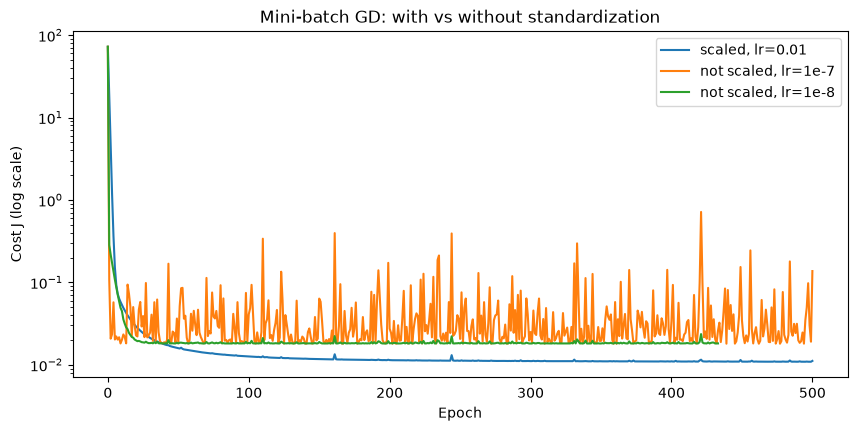

Scaled:                final train cost = 0.01113
Not scaled, lr=1e-7:   final train cost = 0.137
Not scaled, lr=1e-8:   final train cost = 0.01815


In [36]:
plt.figure(figsize=(10, 4.5))
plt.plot(histories['Mini-batch GD'], label=f"scaled, lr={best_lr['Mini-batch GD']}")
plt.plot(raw_histories[1e-7], label='not scaled, lr=1e-7')
plt.plot(raw_histories[1e-8], label='not scaled, lr=1e-8')
plt.yscale('log')
plt.xlabel('Epoch')
plt.ylabel('Cost J (log scale)')
plt.title('Mini-batch GD: with vs without standardization')
plt.legend()
plt.show()

print('Scaled:                final train cost =', round(histories['Mini-batch GD'][-1], 5))
print('Not scaled, lr=1e-7:   final train cost =', round(raw_histories[1e-7][-1], 5))
print('Not scaled, lr=1e-8:   final train cost =', round(raw_histories[1e-8][-1], 5))

**Результати:**
- Без масштабування вже при $\alpha \geq 3 \cdot 10^{-7}$ навчання **розходиться** (cost → ∞ за 3–7 епох),
  а зі стандартизацією працює $\alpha = 0.01$ — різниця у 100 000 разів.
- З $\alpha = 10^{-7}$ навчання формально не розходиться, але cost весь час стрибає (від ~0.02 до ~0.7) і закінчується на 0.137 —
  у 12 разів гірше, ніж зі стандартизацією (0.0111).
- З $\alpha = 10^{-8}$ навчання стабільне, але cost "застрягає" на 0.018 (на ~60% гірше), а зміна cost стає меншою за $10^{-7}$,
  і алгоритм **хибно вирішує, що зійшовся** (зупинка на 433-й епосі), хоча до мінімуму ще далеко.

**Геометричне пояснення** (лекція 1, "Entering Parameter Space" та "Feature Scaling"):
- Градієнт по вазі $w_j$ дорівнює $\frac{1}{m}\sum (\hat{y} - y) \, x_j$, тобто він **пропорційний величині ознаки** $x_j$.
  Для `GrLivArea` (~1500) чи `YearBuilt` (~2000) градієнт величезний, а для `FullBath` (~2), районів (0/1) і bias — крихітний.
- Через це "чаша" функції втрат стає дуже **витягнутим еліпсом**: в одних напрямках (великі ознаки) стінки дуже круті,
  в інших (малі ознаки, bias) — майже пласке дно.
- Learning rate один для всіх напрямків. Щоб не "вилетіти" по крутому напрямку, $\alpha$ має бути крихітним ($10^{-7}$).
  Але з таким $\alpha$ по пологих напрямках модель майже не рухається: ваги районів, `FullBath`, `OverallQual` і bias практично
  не вчаться. Тому cost зупиняється на поганому рівні, а по крутому напрямку модель ще й "стрибає" від стінки до стінки (зигзаг) —
  звідси коливання на графіку.
- Після стандартизації всі ознаки мають однаковий масштаб, "чаша" стає майже круглою, градієнт показує прямо на мінімум,
  і можна брати великий $\alpha$ → швидка і стабільна збіжність.

---
## Висновки

1. **Дані.** Ames Housing: 2930 будинків, 82 колонки. Ціна сильно асиметрична, тому прогнозували log(SalePrice).
   Дані розбили 70/15/15 **до** будь-якої обробки; кореляції, медіани, $\mu$, $\sigma$ та список категорій рахували тільки на Train,
   щоб уникнути витоку даних. З Train прибрали 2 явні викиди (недобудовані величезні будинки).
2. **Ознаки.** 7 числових ознак + `KitchenQual` (ordinal) + `Neighborhood` (one-hot) — разом 36 колонок.
   Ознаки-дублікати (`GarageArea`, `1stFlrSF`, `TotRmsAbvGrd`, `GarageYrBlt`) прибрали, щоб не було мультиколінеарності.
3. **Модель.** Лінійна регресія, функція втрат, градієнти та три варіанти GD написані на `numpy` без циклів по прикладах;
   градієнт перевірено чисельно. Бонус: Normal Equation (через `pinv`) дав ту саму якість, що підтверджує правильність GD;
   звичайна `inv` не спрацювала через пастку фіктивних змінних.
4. **Порівняння GD.** Усі три методи дійшли до одного мінімуму (cost ≈ 0.011), $R^2 \approx 0.86–0.90$ на всіх вибірках,
   перенавчання немає. Batch GD — найстабільніший, але найповільніший за епохами; SGD — найшумніший;
   Mini-batch — найкращий компроміс між швидкістю і стабільністю.
5. **Припущення.** Лінійність і гомоскедастичність приблизно виконуються, мультиколінеарності немає (VIF < 3),
   а нормальність залишків порушена через "важкий" лівий хвіст (будинки, продані нетипово дешево).
6. **Експеримент А.** Без стандартизації GD або розходиться, або застрягає з набагато більшою помилкою (на 60% – у 12 разів).
   Масштабування ознак для градієнтного спуску — обов'язковий крок.

**Що можна покращити:** додати `SaleCondition` (або прибрати продажі `Abnorml`), щоб пояснити нетипово дешеві продажі; спробувати поліноміальні ознаки;
при великій кількості ознак — додати Ridge-регуляризацію.